# Validación cruzada temporal: la fuga que hace brillar a un modelo sin señal

**Perfil:** Cuantitativo y ciencia de datos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

En series de tiempo con etiquetas que **se solapan**, la validación cruzada aleatoria mide la memoria del modelo, no su capacidad de predecir. ¿Cuánto infla el AUC cuando **no hay ninguna señal**? ¿Corrigen el problema la validación contigua, el *walk-forward* y la validación con **purga y embargo**? ¿Y qué le pasa a la **selección de hiperparámetros**?

## Recorrido

1. Un caso mínimo: un único predictor (el tiempo) sobre una serie persistente.
2. Un mundo financiero con **etiquetas a 5 días que se solapan**, sin señal y con señal débil.
3. **Cuatro esquemas de validación:** aleatoria, contigua, *walk-forward* y purga + embargo, contra el AUC verdadero fuera de muestra.
4. **Selección de hiperparámetros** bajo validación con fuga.
5. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.metrics import roc_auc_score, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## 2. Un caso mínimo: el tiempo como único predictor

Una serie **muy persistente** $y_t=0{,}98\,y_{t-1}+\varepsilon_t$ y un solo predictor: el índice de tiempo. **No hay relación causal alguna**: $t$ no contiene información sobre $y$ más allá de la posición en el tiempo. Con validación aleatoria, el modelo **interpola** entre observaciones vecinas; con validación temporal, tiene que **extrapolar**.

In [2]:
rg = np.random.default_rng(71); n = 1500; y = np.zeros(n)
for i in range(1, n): y[i] = 0.98 * y[i - 1] + rg.normal()
Xt = np.arange(n).reshape(-1, 1)

def r2_cv(splitter):
    sc = []
    for tr, te in splitter.split(Xt):
        m = RandomForestRegressor(n_estimators=80, random_state=0, n_jobs=-1).fit(Xt[tr], y[tr]); sc.append(r2_score(y[te], m.predict(Xt[te])))
    return float(np.mean(sc))

caso_min = {"KFold aleatorio": r2_cv(KFold(5, shuffle=True, random_state=0)), "KFold contiguo": r2_cv(KFold(5, shuffle=False)), "TimeSeriesSplit (walk-forward)": r2_cv(TimeSeriesSplit(5))}
pd.Series(caso_min, name="R2 medio").to_frame().round(3)

,R2 medio
KFold aleatorio,0.9610
KFold contiguo,-0.7980
TimeSeriesSplit (walk-forward),-0.5830


In [3]:
print("Lectura:")
print(f"  Con validacion aleatoria el R2 es {caso_min['KFold aleatorio']:.2f} (parece un modelo casi perfecto); con validacion temporal es {caso_min['TimeSeriesSplit (walk-forward)']:.2f} (negativo: peor que predecir la media).")
print("  El predictor (el indice de tiempo) no contiene informacion causal: el 'exito' era interpolacion entre vecinos en el tiempo.")

Lectura:
  Con validacion aleatoria el R2 es 0.96 (parece un modelo casi perfecto); con validacion temporal es -0.58 (negativo: peor que predecir la media).
  El predictor (el indice de tiempo) no contiene informacion causal: el 'exito' era interpolacion entre vecinos en el tiempo.


## 3. Un mundo financiero con etiquetas solapadas

Retornos diarios con volatilidad variable. En cada día $t$ se calculan **características** con retornos hasta $t$ (rendimiento de 1, 5, 20 y 60 días y volatilidad de 20 días) y la **etiqueta** es $y_t=\mathbf 1\{r_{t+1}+\dots+r_{t+5}>0\}$: el signo del retorno de los **próximos 5 días**. Dos muestras vecinas $t,t+1$ comparten **4 de 5 días** de la etiqueta y casi todas sus ventanas de características. Hay dos mundos:

- **Sin señal:** los retornos son independientes: el AUC verdadero de cualquier modelo es **0,5**.
- **Señal débil:** el retorno esperado depende de una **tendencia lenta** (autorregresiva, $\rho=0{,}97$) que la característica de 60 días capta con ruido. El AUC verdadero es algo mayor que 0,5 (para un modelo lineal).

In [4]:
H = 5; L = 60            # horizonte de la etiqueta y ventana maxima de las caracteristicas

def mundo(n, seed, senal):
    rg = np.random.default_rng(seed); T = n + L + H
    vol = 0.01 * np.exp(0.4 * np.cumsum(rg.normal(0, 0.05, T)) * 0.2)
    tend = np.zeros(T)
    if senal:
        for t in range(1, T): tend[t] = 0.97 * tend[t - 1] + rg.normal(0, 0.00025)
    r = tend + vol * rg.standard_normal(T)
    ac = np.concatenate([[0], np.cumsum(r)])
    s = lambda a, b: ac[a:b]
    t_idx = np.arange(L, L + n)
    X = np.column_stack([r[t_idx], ac[t_idx + 1] - ac[t_idx + 1 - 5], ac[t_idx + 1] - ac[t_idx + 1 - 20], ac[t_idx + 1] - ac[t_idx + 1 - 60],
                         np.array([r[t - 19:t + 1].std() for t in t_idx])])
    y = (ac[t_idx + 1 + H] - ac[t_idx + 1] > 0).astype(int)
    return X, y

Xs, ys = mundo(2000, 1, senal=False)
vecino = np.corrcoef(ys[:-1], ys[1:])[0, 1]
print(f"n={len(ys)} | tasa de y=1: {ys.mean():.3f} | autocorrelacion de la etiqueta (rezago 1) = {vecino:.2f} (por el solape de ventanas)")

n=2000 | tasa de y=1: 0.491 | autocorrelacion de la etiqueta (rezago 1) = 0.58 (por el solape de ventanas)


## 4. Cuatro esquemas de validación

1. **KFold aleatorio:** las muestras se reparten al azar entre entrenamiento y prueba.
2. **KFold contiguo:** bloques consecutivos, **sin purga** (solo evita el barajado).
3. **Walk-forward** (`TimeSeriesSplit`): entrena con el pasado, prueba con el futuro inmediato.
4. **Purga + embargo:** como el KFold contiguo, pero se **eliminan del entrenamiento** las muestras cuyas ventanas (de características o de etiqueta) **se solapan** con las del bloque de prueba, más una franja de embargo alrededor.

Se compara el AUC que **estima cada esquema** con el AUC **verdadero** de los mismos modelos en un período futuro **independiente** (datos frescos del mismo proceso).

In [5]:
class PurgadoKFold:
    def __init__(self, n_splits=5, purga=L + H, embargo=10): self.k, self.purga, self.emb = n_splits, purga, embargo
    def split(self, X):
        n = len(X); bordes = np.linspace(0, n, self.k + 1).astype(int)
        for a, b in zip(bordes[:-1], bordes[1:]):
            te = np.arange(a, b); lim_inf, lim_sup = a - self.purga - self.emb, b + self.purga + self.emb
            tr = np.array([i for i in range(n) if i < lim_inf or i >= lim_sup]); yield tr, te

ESQUEMAS = {"KFold aleatorio": lambda: KFold(5, shuffle=True, random_state=0), "KFold contiguo": lambda: KFold(5, shuffle=False),
            "Walk-forward": lambda: TimeSeriesSplit(5), "Purga + embargo": lambda: PurgadoKFold(5)}
MODELOS = {"bosque aleatorio": lambda: RandomForestClassifier(n_estimators=60, min_samples_leaf=1, random_state=0, n_jobs=-1),
           "logistica": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))}

def auc_cv(X, y, esquema, modelo):
    sc = []
    for tr, te in ESQUEMAS[esquema]().split(X):
        if len(np.unique(y[te])) < 2 or len(np.unique(y[tr])) < 2: continue
        m = MODELOS[modelo]().fit(X[tr], y[tr]); sc.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
    return float(np.mean(sc))

def auc_verdadero(X, y, modelo, senal, seed):
    m = MODELOS[modelo]().fit(X, y); Xf, yf = mundo(6000, seed, senal); return roc_auc_score(yf, m.predict_proba(Xf)[:, 1])

def experimento(senal, R=10, n=1800, seed0=0):
    filas = []
    for i in range(R):
        X, y = mundo(n, seed0 + i, senal)
        for modelo in MODELOS:
            ver = auc_verdadero(X, y, modelo, senal, 50_000 + seed0 + i)
            filas.append({"modelo": modelo, "esquema": "AUC VERDADERO (datos frescos)", "AUC": ver})
            for esq in ESQUEMAS: filas.append({"modelo": modelo, "esquema": esq, "AUC": auc_cv(X, y, esq, modelo)})
    return pd.DataFrame(filas)

res0 = experimento(False, seed0=100); res1 = experimento(True, seed0=200)
def tabla(res): return res.pivot_table(index="esquema", columns="modelo", values="AUC").loc[["AUC VERDADERO (datos frescos)"] + list(ESQUEMAS)]
print("MUNDO SIN SENAL (AUC verdadero esperado = 0.5):"); print(tabla(res0).round(3).to_string())
print("\nMUNDO CON SENAL DEBIL:"); print(tabla(res1).round(3).to_string())

MUNDO SIN SENAL (AUC verdadero esperado = 0.5):
modelo                         bosque aleatorio  logistica
esquema                                                   
AUC VERDADERO (datos frescos)            0.5110     0.5050
KFold aleatorio                          0.6360     0.5360
KFold contiguo                           0.4940     0.5090
Walk-forward                             0.5030     0.5000
Purga + embargo                          0.4950     0.5140

MUNDO CON SENAL DEBIL:
modelo                         bosque aleatorio  logistica
esquema                                                   
AUC VERDADERO (datos frescos)            0.5000     0.5200
KFold aleatorio                          0.6550     0.5460
KFold contiguo                           0.5030     0.5230
Walk-forward                             0.4950     0.5160
Purga + embargo                          0.5010     0.5240


In [6]:
t0, t1 = tabla(res0), tabla(res1)
print("Lectura (bosque aleatorio, mundo SIN senal; el modelo NO puede predecir nada):")
for esq in ESQUEMAS: print(f"  {esq:18s}: AUC estimado {t0.loc[esq, 'bosque aleatorio']:.3f} (verdadero {t0.loc['AUC VERDADERO (datos frescos)', 'bosque aleatorio']:.3f}) -> inflado en {t0.loc[esq, 'bosque aleatorio'] - t0.loc['AUC VERDADERO (datos frescos)', 'bosque aleatorio']:+.3f}")
print()
print("Lectura (bosque aleatorio, mundo con SENAL DEBIL):")
for esq in ESQUEMAS: print(f"  {esq:18s}: AUC estimado {t1.loc[esq, 'bosque aleatorio']:.3f} (verdadero {t1.loc['AUC VERDADERO (datos frescos)', 'bosque aleatorio']:.3f}) -> sesgo {t1.loc[esq, 'bosque aleatorio'] - t1.loc['AUC VERDADERO (datos frescos)', 'bosque aleatorio']:+.3f}")
print()
print(f"  La logistica (poco flexible) apenas puede aprovechar la fuga: AUC estimado con KFold aleatorio {t0.loc['KFold aleatorio', 'logistica']:.3f} en el mundo sin senal.")
print()
print("Lectura (logistica, mundo con SENAL DEBIL): la unica que puede captarla.")
for esq in ESQUEMAS: print(f"  {esq:18s}: AUC estimado {t1.loc[esq, 'logistica']:.3f} (verdadero {t1.loc['AUC VERDADERO (datos frescos)', 'logistica']:.3f}) -> sesgo {t1.loc[esq, 'logistica'] - t1.loc['AUC VERDADERO (datos frescos)', 'logistica']:+.3f}")
print(f"  Con senal debil el bosque NO la capta (AUC verdadero {t1.loc['AUC VERDADERO (datos frescos)', 'bosque aleatorio']:.3f}) mientras la logistica si ({t1.loc['AUC VERDADERO (datos frescos)', 'logistica']:.3f}): un modelo mas flexible no es mejor cuando la senal es debil y lineal.")
n_front = (L + H) * 2 / (len(ys) / 5)
print(f"  El KFold contiguo NO se infla aqui porque el solape solo afecta a las fronteras de cada bloque (~{n_front:.0%} de las muestras de un pliegue): la fuga seria mayor con pliegues cortos o ventanas mas largas.")

Lectura (bosque aleatorio, mundo SIN senal; el modelo NO puede predecir nada):
  KFold aleatorio   : AUC estimado 0.636 (verdadero 0.511) -> inflado en +0.125
  KFold contiguo    : AUC estimado 0.494 (verdadero 0.511) -> inflado en -0.018
  Walk-forward      : AUC estimado 0.503 (verdadero 0.511) -> inflado en -0.008
  Purga + embargo   : AUC estimado 0.495 (verdadero 0.511) -> inflado en -0.017

Lectura (bosque aleatorio, mundo con SENAL DEBIL):
  KFold aleatorio   : AUC estimado 0.655 (verdadero 0.500) -> sesgo +0.155
  KFold contiguo    : AUC estimado 0.503 (verdadero 0.500) -> sesgo +0.003
  Walk-forward      : AUC estimado 0.495 (verdadero 0.500) -> sesgo -0.005
  Purga + embargo   : AUC estimado 0.501 (verdadero 0.500) -> sesgo +0.001

  La logistica (poco flexible) apenas puede aprovechar la fuga: AUC estimado con KFold aleatorio 0.536 en el mundo sin senal.

Lectura (logistica, mundo con SENAL DEBIL): la unica que puede captarla.
  KFold aleatorio   : AUC estimado 0.546 (verdad

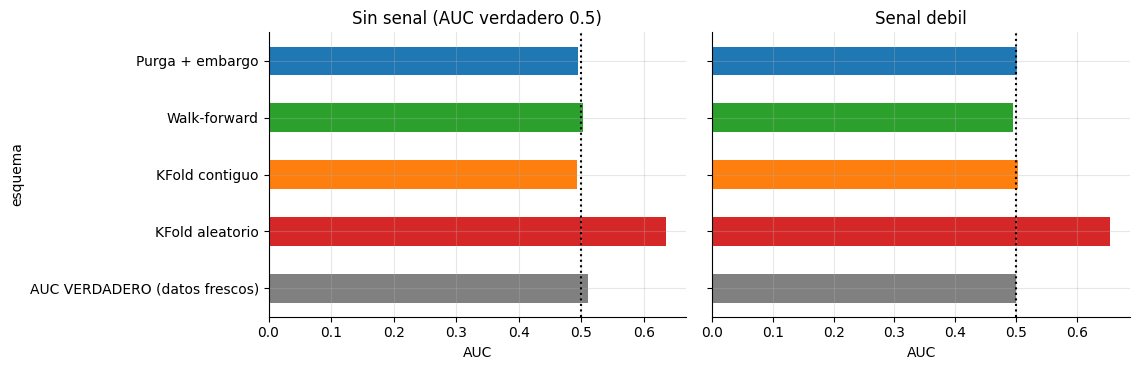

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for a, (t_, titulo) in zip(ax, ((t0, "Sin senal (AUC verdadero 0.5)"), (t1, "Senal debil"))):
    t_["bosque aleatorio"].plot(kind="barh", ax=a, color=["gray"] + ["C3", "C1", "C2", "C0"]); a.axvline(0.5, color="k", ls=":"); a.set_title(titulo); a.set_xlabel("AUC")
plt.tight_layout(); plt.show()

**Qué se aprende.** La fuga **no necesita** una señal real ni un error de programación sofisticado: basta con muestras **vecinas** (que comparten ventanas de características y de etiqueta) repartidas entre entrenamiento y prueba. Un modelo flexible las **memoriza**. La logística, con poca capacidad para memorizar, casi no se engaña. La purga y el embargo eliminan el solape y devuelven una estimación honesta.

## 5. Selección de hiperparámetros bajo validación con fuga

El tamaño mínimo de hoja del bosque controla cuánto puede **memorizar**: `min_samples_leaf=1` memoriza, 100 no. Se elige por validación cruzada y se mide el **AUC verdadero** de la elección. Con fuga, la validación **premia** a los modelos que memorizan.

In [8]:
HOJAS = [1, 5, 20, 100]
def seleccion(senal, R=10, seed0=0):
    filas = []
    for i in range(R):
        X, y = mundo(1800, seed0 + i, senal); Xf, yf = mundo(6000, 70_000 + seed0 + i, senal)
        for esq in ("KFold aleatorio", "Purga + embargo"):
            punt = {}
            for h in HOJAS:
                sc = []
                for tr, te in ESQUEMAS[esq]().split(X):
                    m = RandomForestClassifier(n_estimators=40, min_samples_leaf=h, random_state=0, n_jobs=-1).fit(X[tr], y[tr]); sc.append(roc_auc_score(y[te], m.predict_proba(X[te])[:, 1]))
                punt[h] = np.mean(sc)
            elegido = max(punt, key=punt.get)
            m = RandomForestClassifier(n_estimators=40, min_samples_leaf=elegido, random_state=0, n_jobs=-1).fit(X, y)
            filas.append({"esquema": esq, "hoja_elegida": elegido, "AUC_CV_del_elegido": punt[elegido], "AUC_verdadero_del_elegido": roc_auc_score(yf, m.predict_proba(Xf)[:, 1])})
    return pd.DataFrame(filas)

sel0 = seleccion(False, seed0=300)
resumen_sel = sel0.groupby("esquema").agg(hoja_media=("hoja_elegida", "mean"), prop_hoja1=("hoja_elegida", lambda s: (s == 1).mean()), AUC_CV=("AUC_CV_del_elegido", "mean"), AUC_verdadero=("AUC_verdadero_del_elegido", "mean"))
resumen_sel.round(3)

,hoja_media,prop_hoja1,AUC_CV,AUC_verdadero
esquema,,,,
KFold aleatorio,2.2000,0.7000,0.6370,0.4970
Purga + embargo,80.2000,0.2000,0.5090,0.5010


In [9]:
a, b = resumen_sel.loc["KFold aleatorio"], resumen_sel.loc["Purga + embargo"]
print("Lectura (mundo SIN senal; el AUC verdadero de cualquier modelo es 0.5):")
print(f"  KFold aleatorio elige min_samples_leaf=1 (memorizar) en {a['prop_hoja1']:.0%} de las repeticiones; purga + embargo, en {b['prop_hoja1']:.0%}.")
print(f"  El AUC que reporta el CV del modelo elegido: {a['AUC_CV']:.3f} (aleatorio) frente a {b['AUC_CV']:.3f} (purga). El AUC verdadero de lo elegido es {a['AUC_verdadero']:.3f} y {b['AUC_verdadero']:.3f}.")
print("  Con fuga, el criterio de seleccion premia la memorizacion y ademas reporta una puntuacion que no existe fuera de muestra.")

Lectura (mundo SIN senal; el AUC verdadero de cualquier modelo es 0.5):
  KFold aleatorio elige min_samples_leaf=1 (memorizar) en 70% de las repeticiones; purga + embargo, en 20%.
  El AUC que reporta el CV del modelo elegido: 0.637 (aleatorio) frente a 0.509 (purga). El AUC verdadero de lo elegido es 0.497 y 0.501.
  Con fuga, el criterio de seleccion premia la memorizacion y ademas reporta una puntuacion que no existe fuera de muestra.


## 6. Pruebas automáticas

In [10]:
# 6.1 caso minimo: el R2 aleatorio es enorme y el temporal es negativo
assert caso_min["KFold aleatorio"] > 0.8 and caso_min["TimeSeriesSplit (walk-forward)"] < 0
# 6.2 el solape de etiquetas es real
assert vecino > 0.5
# 6.3 mundo sin senal: el AUC verdadero es ~0.5 para ambos modelos
for mdl in MODELOS: assert abs(t0.loc["AUC VERDADERO (datos frescos)", mdl] - 0.5) < 0.03
# 6.4 la fuga: el KFold aleatorio infla el AUC del bosque aleatorio claramente por encima de 0.5 sin senal; el esquema con purga no
assert t0.loc["KFold aleatorio", "bosque aleatorio"] > 0.58
assert abs(t0.loc["Purga + embargo", "bosque aleatorio"] - 0.5) < 0.04
assert t0.loc["KFold aleatorio", "bosque aleatorio"] > t0.loc["Purga + embargo", "bosque aleatorio"] + 0.08
# 6.5 walk-forward no esta inflado; el KFold contiguo sin purga esta mucho menos inflado que el aleatorio
assert abs(t0.loc["Walk-forward", "bosque aleatorio"] - 0.5) < 0.05
assert t0.loc["KFold contiguo", "bosque aleatorio"] < t0.loc["KFold aleatorio", "bosque aleatorio"]
# 6.6 la logistica (poca capacidad de memorizar) casi no se infla
assert t0.loc["KFold aleatorio", "logistica"] < 0.56
# 6.7 con senal debil, el AUC verdadero esta por encima de 0.5 y el esquema con purga lo estima sin la inflacion enorme del aleatorio
assert t1.loc["AUC VERDADERO (datos frescos)", "bosque aleatorio"] > 0.5 and t1.loc["AUC VERDADERO (datos frescos)", "logistica"] > 0.5
assert abs(t1.loc["Purga + embargo", "bosque aleatorio"] - t1.loc["AUC VERDADERO (datos frescos)", "bosque aleatorio"]) < abs(t1.loc["KFold aleatorio", "bosque aleatorio"] - t1.loc["AUC VERDADERO (datos frescos)", "bosque aleatorio"])
# 6.8 seleccion de hiperparametros: la fuga premia memorizar y reporta una puntuacion inflada
assert a["prop_hoja1"] > b["prop_hoja1"] and a["hoja_media"] < b["hoja_media"]
assert a["AUC_CV"] > b["AUC_CV"] + 0.05 and abs(a["AUC_verdadero"] - 0.5) < 0.04
# 6.9 el esquema con purga es correcto: sin solape entre las ventanas de entrenamiento y las de prueba
for tr, te in PurgadoKFold(5).split(np.zeros((500, 1))):
    assert (np.abs(tr[:, None] - te[None, :]) > L + H).all(), "quedaron muestras de entrenamiento dentro de la franja de purga"
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Caso mínimo | Con un predictor sin información, la validación aleatoria da R² ≈ 0,9; la temporal da negativo | Si el modelo predice 'demasiado bien', sospechar de fuga |
| Etiquetas solapadas | La fuga infla el AUC de un bosque aleatorio sin señal alguna | Ningún modelo debe 'predecir' lo que no contiene información |
| Esquemas | El aleatorio está inflado; el contiguo menos; walk-forward y purga + embargo dan estimaciones honestas | Usar purga + embargo cuando haya ventanas solapadas |
| Modelo simple | La logística casi no se engaña porque no puede memorizar | La fuga afecta sobre todo a modelos flexibles |
| Hiperparámetros | Con fuga se eligen configuraciones que memorizan y se reporta una puntuación que no existe fuera de muestra | Seleccionar con el mismo esquema honesto con que se evalúa |

**Límites que no deben ocultarse**

- Los retornos y la señal son sintéticos y simples; en datos reales el solape entre muestras puede ser más complejo (varias escalas, etiquetas de longitud variable).
- La franja de purga y el embargo se fijaron por la ventana máxima conocida; con ventanas desconocidas hay que sobreestimarlas.
- Se usan pocas repeticiones (10) y bosques pequeños para acotar el tiempo; las diferencias pequeñas están dentro del ruido.
- Walk-forward usa menos datos de entrenamiento en los primeros pliegues, lo que lo hace más conservador, no más sesgado.
- Datos sintéticos: ningún valor numérico es extrapolable a un problema real.